##### Copyright 2026 The Contributors

Licensed under the Apache License, Version 2.0 (the "License");
you may not use this file except in compliance with the License.
See the LICENSE file in the repository root.


# 00 — Data contract, real-data ingestion, and synthetic sample

This notebook is the **only** place you need to touch to plug in your own data.
Everything downstream (`01`..`06`) reads `patients.csv` / `hexagons.csv` /
`contacts.csv` from `DATA_DIR` and does not care whether that data came from
a real export or the synthetic generator below.

## Two supported paths

| Path | When to use | What you run |
| --- | --- | --- |
| **A. Synthetic (default)** | Learning the pipeline, CI, demos | `generate_synthetic_dataset()` |
| **B. Real Nikshay-style export** | You have a real Notification Register CSV | Section 2 of this notebook |

Set `USE_REAL_DATA = True` below once you have a real export path.


In [1]:
import sys
from pathlib import Path

# Make `pipeline` / `utils` importable when Jupyter's cwd is notebooks/
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 60)
print("ROOT =", ROOT)


ROOT = /Users/froncort.ai/Desktop/Froncort/ai-acf-ml-notebooks


In [2]:
USE_REAL_DATA = False  # flip to True and set REAL_REGISTER_PATH below

# Path to a raw Nikshay "Notification Register" export (State/District level
# download from the Nikshay portal, or an equivalent program CSV/XLSX->CSV
# export). This file is NEVER committed to the repo -- keep it outside
# version control (see .gitignore: sample_data/* is ignored except this
# README/.gitkeep).
REAL_REGISTER_PATH = "/path/to/your/Notification Register.csv"


## 1. Data contract

Whichever path you take, the pipeline expects these files in `DATA_DIR`.
Optional columns are used opportunistically -- missing ones just reduce
feature richness, they do not break anything.


In [3]:
from pipeline.sample_data import DATA_CONTRACT
from utils import SAMPLE_DATA_DIR, ensure_dirs

ensure_dirs()
for table, cols in DATA_CONTRACT.items():
    print(f"[{table}]")
    for k, v in cols.items():
        print(f"  {k:<24} {v}")
    print()


[patients]
  patient_id               Unique case id (string or int)
  h3_index                 H3 cell id at your chosen resolution (e.g. res 10)
  diagnosis_date           ISO date when TB was diagnosed
  age                      Age in years (optional but useful)
  site_of_disease          Pulmonary | Extra-pulmonary | Other (optional)
  hiv_status               Positive | Negative | Unknown (optional)
  diabetes_status          Yes | No | Unknown (optional)
  is_recidivism            1 if retreatment / relapse, else 0 (optional)

[hexagons]
  h3_index                 H3 cell id covering the area of interest
  lat                      Cell centroid latitude (optional, for maps)
  lng                      Cell centroid longitude (optional, for maps)
  slum_density             0-1 density / vulnerability proxy (optional)

[contacts]
  h3_index                 H3 of index / contact location (optional file)
  month                    Month (YYYY-MM-01) of contact-tracing activity (optio

## 2. Path B — ingesting a *real* Nikshay-style export

Real Notification Register CSVs (any Indian district, any year) share three
quirks that break a naive `pd.read_csv` -- and none of them are program-specific,
so this section works for **any** district's export, not just one dataset:

1. **~5 metadata rows before the real header** (`@Report Name`, `Data Filter Criteria`, ...)
2. **Health-system hierarchy, not GPS.** Cases carry State -> District -> TB Unit -> Health
   Facility, plus a free-text `Address`. There is no lat/lon column.
3. **Locale dates** like `1/29/25` (M/D/YY).

`pipeline/ingest.py` solves all three generically. We geocode **once per unique
facility** (not per patient) -- the same V1 strategy as production AI-ACF
ingestion -- then convert centroids to H3 and build `hexagons.csv` as the
**list of AOI / region cells**.

### Geocoding providers (pick one)

| Provider | Setup | Notes |
| --- | --- | --- |
| **`google`** (default, V1) | `export GOOGLE_MAPS_API_KEY=...` and `pip install googlemaps` | Matches production quality |
| **`nominatim`** | `pip install geopy` | Free OSM fallback, ~1 req/s |
| Manual | Edit `facility_centroids.csv` lat/lng | Offline correction |

`hexagons.csv` after this step = every H3 cell that appears in your geocoded
patients (plus centroids). For full regional coverage including never-case
hexes, replace it with your GIS AOI hex list before notebook `01`.


In [4]:
from pipeline.ingest import (
    load_raw_register, standardize_patients, build_facility_table,
    geocode_facility_table, assign_h3_from_facility_table, build_hexagon_table,
    NOTIFICATION_REGISTER_COLUMN_MAP,
)
from utils import save_data

if USE_REAL_DATA:
    # Step 2.1 — load, auto-skipping the metadata rows above the real header
    raw = load_raw_register(REAL_REGISTER_PATH)
    print(raw.shape, "raw rows x columns")
    display(raw.head(2))


In [5]:
if USE_REAL_DATA:
    # Step 2.2 — rename known Nikshay columns to our internal schema, parse
    # dates, and derive is_recidivism / infectivity_score. Anything not in
    # NOTIFICATION_REGISTER_COLUMN_MAP is dropped -- extend the map in
    # pipeline/ingest.py if your export has extra columns you want to keep.
    patients_raw = standardize_patients(raw, column_map=NOTIFICATION_REGISTER_COLUMN_MAP)
    print(patients_raw.shape)
    print("\nColumn dtypes:")
    print(patients_raw.dtypes)
    print("\nMissingness by column:")
    print((patients_raw.isna().mean() * 100).round(1).sort_values(ascending=False))


In [6]:
if USE_REAL_DATA:
    # Step 2.3 — quick sanity checks before spending time on geocoding
    print("Date range:", patients_raw["diagnosis_date"].min(), "->", patients_raw["diagnosis_date"].max())
    print("\nSite of disease:\n", patients_raw.get("site_of_disease", pd.Series(dtype=object)).value_counts())
    print("\nis_recidivism rate: %.2f%%" % (100 * patients_raw["is_recidivism"].mean()))
    print("\nRows per facility (top 10):")
    print(patients_raw["facility_name"].value_counts().head(10))


In [7]:
if USE_REAL_DATA:
    # Step 2.4 — build the unique-facility table that needs a lat/lon centroid.
    # This is the ONLY thing that needs geocoding, no matter how many patients
    # you have. Save it so you (or a colleague) can hand-correct any row.
    facilities = build_facility_table(patients_raw)
    facilities_path = SAMPLE_DATA_DIR / "facility_centroids.csv"
    save_data(facilities, facilities_path)
    print(f"Saved {len(facilities)} facilities -> {facilities_path}")
    print("Fill in lat/lng manually (Google Maps / OSM) OR run automatic geocoding below.")
    facilities.head()


In [8]:
if USE_REAL_DATA:
    # Step 2.5 — geocode facilities (V1-style Google Maps by default).
    # Requires: export GOOGLE_MAPS_API_KEY=...  and  pip install googlemaps
    # Free fallback: provider="nominatim" (+ pip install geopy)
    # Safe to re-run: only geocodes rows still missing lat/lng.
    # If you already filled facilities['lat']/['lng'] by hand, skip this cell.
    import os
    # os.environ["GOOGLE_MAPS_API_KEY"] = "YOUR_KEY"  # prefer exporting in the shell

    facilities = geocode_facility_table(facilities, provider="google")
    # facilities = geocode_facility_table(facilities, provider="nominatim")  # free fallback
    save_data(facilities, facilities_path)
    coverage = facilities["lat"].notna().mean() * 100
    print(f"Facility geocoding coverage: {coverage:.1f}%")


In [9]:
if USE_REAL_DATA:
    # Step 2.6 — attach facility centroid -> H3 index (resolution 10 ~65m
    # hexagons; use 9 for ~175m if your facility density is sparse) and build
    # the hexagons table the rest of the pipeline expects.
    patients_final = assign_h3_from_facility_table(patients_raw, facilities, resolution=10)
    hexagons_final = build_hexagon_table(patients_final)

    save_data(patients_final, SAMPLE_DATA_DIR / "patients.csv")
    save_data(hexagons_final, SAMPLE_DATA_DIR / "hexagons.csv")
    print(f"Saved {len(patients_final)} patients across {len(hexagons_final)} hexagons -> {SAMPLE_DATA_DIR}")
    print("You can now skip Section 3 and go straight to notebook 01.")


## 3. Path A — synthetic sample data (default quick start)

Generates small, spatially-clustered, temporally-persistent fake TB case
data so every notebook runs end-to-end **without any real dataset**. This is
what runs by default (`USE_REAL_DATA = False`).


In [10]:
from pipeline.sample_data import generate_synthetic_dataset

if not USE_REAL_DATA:
    # n_hex/n_months sized so the gate model actually has enough rows to
    # respect production's min_child_weight=50 (see pipeline/training.py) --
    # a too-small demo would make Stage 1 degenerate (0 valid splits).
    patients, hexagons, contacts = generate_synthetic_dataset(
        n_hex=300,      # number of H3 cells in the synthetic AOI
        n_months=20,    # months of history to simulate
        seed=42,        # change this to get a different (but reproducible) run
        out_dir=SAMPLE_DATA_DIR,
    )
    print(f"patients={len(patients)}  hexagons={len(hexagons)}  contacts={len(contacts)}")
    display(patients.head())
    display(hexagons.head())


INFO | Saved 6795 rows -> /Users/froncort.ai/Desktop/Froncort/ai-acf-ml-notebooks/sample_data/patients.csv


INFO | Saved 300 rows -> /Users/froncort.ai/Desktop/Froncort/ai-acf-ml-notebooks/sample_data/hexagons.csv


INFO | Saved 1200 rows -> /Users/froncort.ai/Desktop/Froncort/ai-acf-ml-notebooks/sample_data/contacts.csv


INFO | Synthetic data: 6795 patients, 300 hexes, 20 months -> /Users/froncort.ai/Desktop/Froncort/ai-acf-ml-notebooks/sample_data


patients=6795  hexagons=300  contacts=1200


,patient_id,h3_index,diagnosis_date,age,site_of_disease,hiv_status,diabetes_status,is_recidivism,infectivity_score
0,P00000,8a60885010cffff,2024-01-17,67,Pulmonary,Negative,Yes,0,1.0
1,P00001,8a60885010cffff,2024-01-25,54,Extra-pulmonary,Negative,No,0,0.2
2,P00002,8a60885010cffff,2024-01-17,44,Other,Negative,Yes,0,0.2
3,P00003,8a60885010d7fff,2024-01-12,64,Pulmonary,Negative,No,0,1.0
4,P00004,8a60885010dffff,2024-01-04,27,Pulmonary,Negative,No,0,1.0


,h3_index,lat,lng,slum_density
0,8a60885010c7fff,18.488178,73.812305,0.746560
1,8a60885010cffff,18.511818,73.765387,0.444991
2,8a60885010d7fff,18.468368,73.803288,0.822738
3,8a60885010dffff,18.529519,73.792191,0.677631
4,8a60885010effff,18.507367,73.836957,0.134760


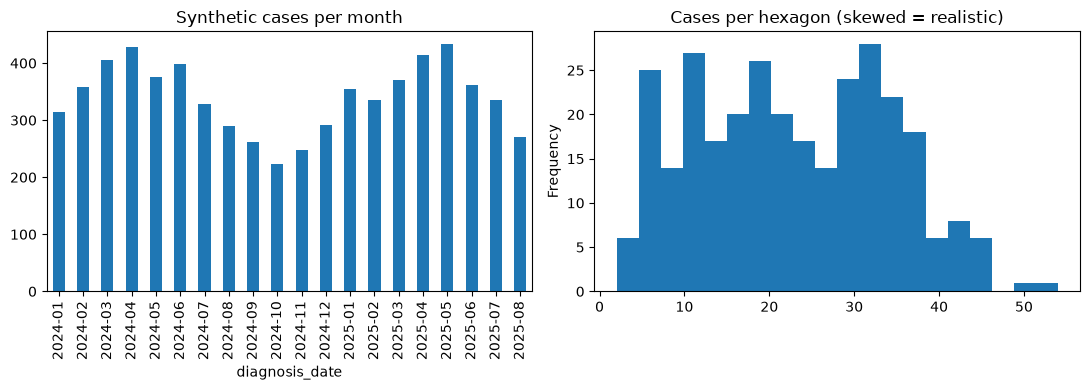

In [11]:
if not USE_REAL_DATA:
    # Visual sanity check: cases per month should show some seasonality +
    # random noise, and cases per hexagon should be right-skewed (a few
    # high-risk cells, many low-risk ones) -- both are true for real TB data.
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    patients["diagnosis_date"].dt.to_period("M").value_counts().sort_index().plot(kind="bar", ax=axes[0])
    axes[0].set_title("Synthetic cases per month")
    patients.groupby("h3_index").size().plot(kind="hist", bins=20, ax=axes[1])
    axes[1].set_title("Cases per hexagon (skewed = realistic)")
    plt.tight_layout()
    plt.show()


## Next

Whichever path you used, `sample_data/patients.csv` and `sample_data/hexagons.csv`
(optionally `contacts.csv`) now exist. Open `01_feature_engineering.ipynb`.
